#IMPORT LIBRARIES


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# LOAD DATASET


In [2]:
df = pd.read_csv("housing.csv")

# EDA


## 1. Missing Value Handling


In [3]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

## 2.Data Structure Check

In [4]:
df.shape

(20640, 10)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [6]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 3.Target Analysis

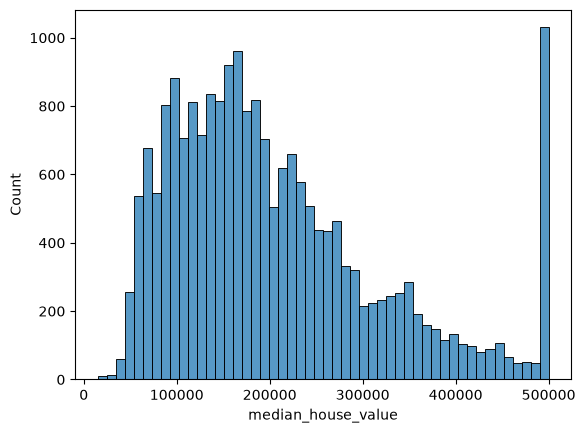

In [7]:
sns.histplot(df["median_house_value"], bins=50)
plt.show()

##4.Correlation Analysis

In [8]:
num_df = df.select_dtypes(include="number")
num_df.corr()["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

##5.Correlation Heatmap

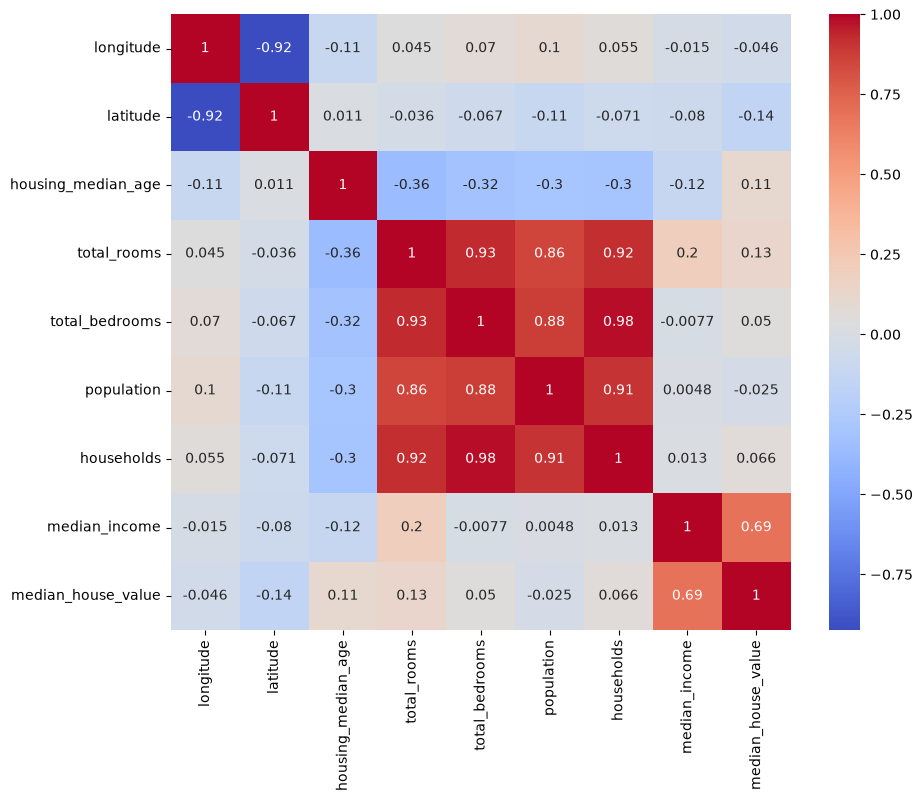

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm")
plt.show()

##6.Geographic Analysis

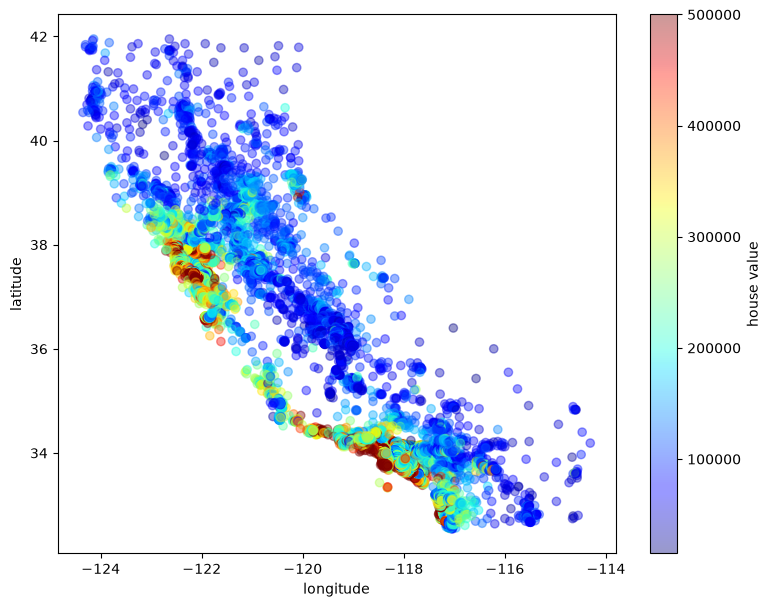

In [10]:
plt.figure(figsize=(9, 7))
plt.scatter(df["longitude"], df["latitude"], c=df["median_house_value"], cmap="jet", alpha=0.4)
plt.colorbar(label="house value")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.show()

##7.Categorical Feature Analysis

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


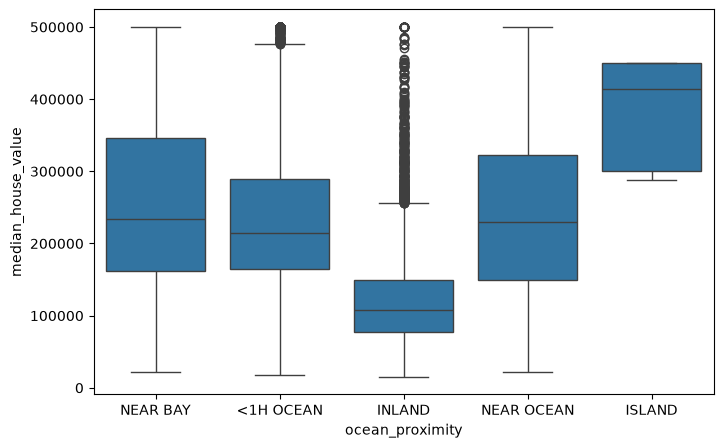

In [11]:
print(df["ocean_proximity"].value_counts())

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="ocean_proximity", y="median_house_value")
plt.show()

# STEP 3: PREPROCESSING

In [12]:
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]
print(X.shape)
print(y.shape)


(20640, 9)
(20640,)


In [13]:
X = pd.get_dummies(X, columns=["ocean_proximity"], dtype=int)
X.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,0,0,0,1,0


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(16512, 13) (4128, 13)


In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(X_train_scaled.shape, X_test_scaled.shape)

(16512, 13) (4128, 13)


#STEP 4: LINEAR REGRESSION

In [16]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

model = LinearRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
print("RMSE:", rmse)
print("R2:", r2)

ValueError: Input X contains NaN.
LinearRegression does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train_scaled, y_train)
rf_pred = rf.predict(X_test_scaled)

print("RMSE:", np.sqrt(mean_squared_error(y_test, rf_pred)))
print("R2:", r2_score(y_test, rf_pred))

RMSE: 48757.633082085245
R2: 0.826159023345961


# STEP:5 FEATURE IMPORTANCE

median_income                 0.485008
ocean_proximity_INLAND        0.142814
longitude                     0.108992
latitude                      0.104619
housing_median_age            0.050451
population                    0.032720
total_rooms                   0.023519
total_bedrooms                0.022254
households                    0.018916
ocean_proximity_NEAR OCEAN    0.005576
ocean_proximity_<1H OCEAN     0.003519
ocean_proximity_NEAR BAY      0.001275
ocean_proximity_ISLAND        0.000337
dtype: float64


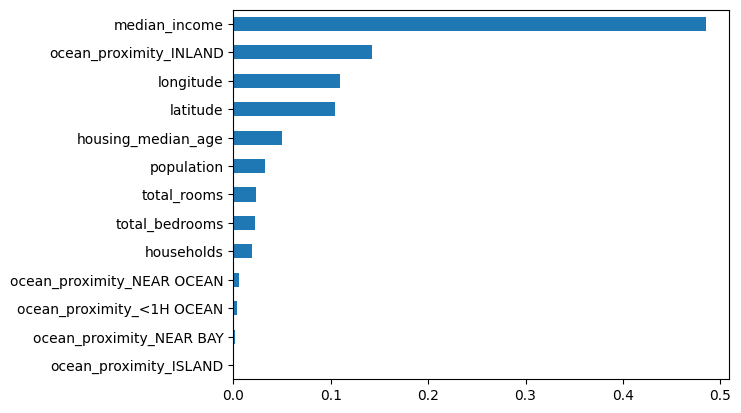

In [ ]:
importances = pd.Series(rf.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)
print(importances)

importances.plot(kind="barh")
plt.gca().invert_yaxis()
plt.show()

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(rf, X_train_scaled, y_train, cv=5,
                         scoring="neg_root_mean_squared_error", n_jobs=-1)
rmse_scores = -scores

print("Fold scores:", rmse_scores.round(0))
print("Mean RMSE:", rmse_scores.mean().round(0))
print("Std:", rmse_scores.std().round(0))

Fold scores: [46851. 52260. 47887. 49331. 50290.]
Mean RMSE: 49324.0
Std: 1883.0


In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {"n_estimators": [100, 200], "max_depth": [20, None]}

grid = GridSearchCV(RandomForestRegressor(random_state=42), param_grid,
                    cv=3, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(X_train_scaled, y_train)

print("Best params:", grid.best_params_)
best_rf = grid.best_estimator_
best_pred = best_rf.predict(X_test_scaled)
print("RMSE:", np.sqrt(mean_squared_error(y_test, best_pred)))
print("R2:", r2_score(y_test, best_pred))

Best params: {'max_depth': None, 'n_estimators': 200}
RMSE: 48714.273862579146
R2: 0.8264680727015061


In [ ]:
lr_pred = model.predict(X_test_scaled)   # Linear Regression (pehle wala 'model')

results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest (default)", "Random Forest (tuned)"],
    "RMSE": [np.sqrt(mean_squared_error(y_test, p)) for p in [lr_pred, rf_pred, best_pred]],
    "R2": [r2_score(y_test, p) for p in [lr_pred, rf_pred, best_pred]],
}).round(3)
print(results)

                     Model       RMSE     R2
0        Linear Regression  69297.717  0.649
1  Random Forest (default)  48757.633  0.826
2    Random Forest (tuned)  48714.274  0.826


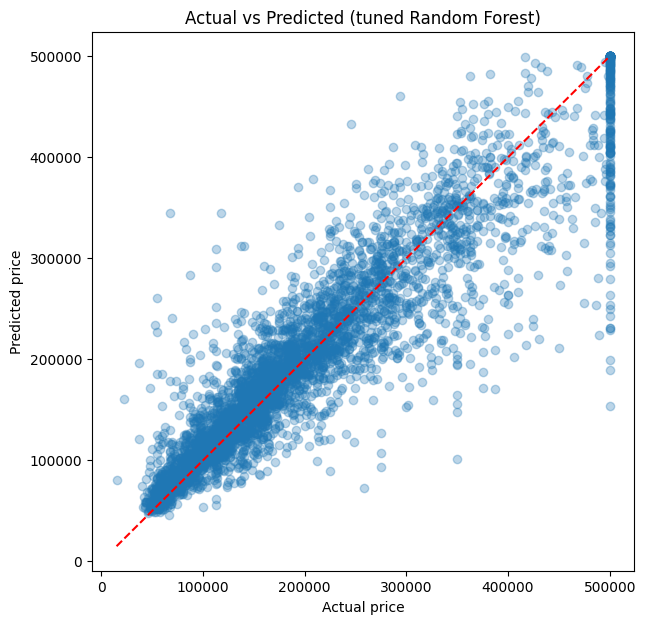

In [ ]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs Predicted (tuned Random Forest)")
plt.show()

median_income                 0.485
ocean_proximity_INLAND        0.143
longitude                     0.110
latitude                      0.105
housing_median_age            0.050
population                    0.033
total_rooms                   0.024
total_bedrooms                0.022
households                    0.019
ocean_proximity_NEAR OCEAN    0.005
ocean_proximity_<1H OCEAN     0.004
ocean_proximity_NEAR BAY      0.001
ocean_proximity_ISLAND        0.000
dtype: float64


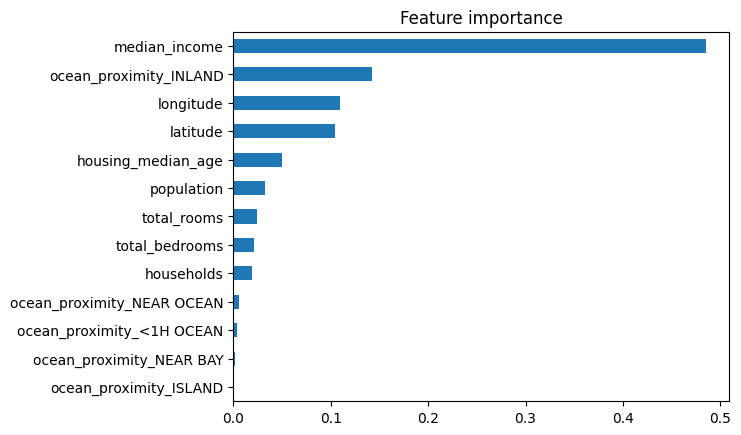

In [ ]:
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.round(3))
importances.plot(kind="barh")
plt.gca().invert_yaxis()
plt.title("Feature importance")
plt.show()

In [ ]:
import joblib
joblib.dump(best_rf, "house_price_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']